In [4]:
import numpy as np
import pandas as pd
# 웹 서버 접속 로그 생성 (가상) — 한 줄이 통째로 문자열
np.random.seed(7)
n_logs = 1500
ips = [f"203.0.113.{k}" for k in range(1, 60)] + [f"198.51.100.{k}" for k in range(1, 60)]
paths = ["/", "/products", "/products/123", "/products/456", "/cart",
         "/checkout", "/login", "/search", "/api/orders"]
methods = ["GET", "GET", "GET", "POST"]
statuses = [200, 200, 200, 200, 200, 404, 500, 301]

# 시각: 7일치, 초 단위로 무작위 발생 후 정렬
log_times = pd.to_datetime("2025-03-01") + pd.to_timedelta(
    np.sort(np.random.randint(0, 7 * 24 * 3600, n_logs)), unit="s")

lines = []
for i in range(n_logs):
    ip = np.random.choice(ips)
    ts_str = log_times[i].strftime("%d/%b/%Y:%H:%M:%S")   # 12/Jan/2025:10:15:32
    m = np.random.choice(methods)
    p = np.random.choice(paths)
    st = np.random.choice(statuses)
    sz = np.random.randint(200, 5000)
    lines.append(f'{ip} - - [{ts_str}] "{m} {p} HTTP/1.1" {st} {sz}')

web_logs = pd.DataFrame({"raw": lines})
print("웹 로그 생성 완료:", web_logs.shape)
print("\n[원본 로그 한 줄은 이렇게 생겼습니다]")
for line in web_logs["raw"].head(3):
    print(line)

웹 로그 생성 완료: (1500, 1)

[원본 로그 한 줄은 이렇게 생겼습니다]
203.0.113.39 - - [01/Mar/2025:00:01:14] "GET / HTTP/1.1" 200 2371
198.51.100.21 - - [01/Mar/2025:00:02:24] "GET / HTTP/1.1" 301 284
198.51.100.17 - - [01/Mar/2025:00:02:28] "GET /search HTTP/1.1" 200 1448


In [5]:
# 시나리오 1 — 정규식으로 6개 필드를 한 번에 추출
pattern = (
    r"(?P<ip>\d+\.\d+\.\d+\.\d+)"        # IP: 숫자.숫자.숫자.숫자
    r" - - \["                            # 고정 구분 부분
    r"(?P<ts>[^\]]+)"                     # 시각: ] 가 아닌 글자들
    r"\] \""                              # ] 와 따옴표
    r"(?P<method>\w+) "                   # 방식: GET/POST
    r"(?P<path>\S+)"                      # 경로: 공백 아닌 글자들
    r"[^\"]*\" "                          # HTTP/1.1 부분 건너뛰기
    r"(?P<status>\d+) "                   # 상태 코드
    r"(?P<size>\d+)"                      # 응답 크기
)
logs = web_logs["raw"].str.extract(pattern)
print("추출된 표:", logs.shape)
print(logs.head())
print("\n추출 실패(어느 한 칸이라도 NaN) 행 수:", logs.isna().any(axis=1).sum())

추출된 표: (1500, 6)
              ip                    ts method       path status  size
0   203.0.113.39  01/Mar/2025:00:01:14    GET          /    200  2371
1  198.51.100.21  01/Mar/2025:00:02:24    GET          /    301   284
2  198.51.100.17  01/Mar/2025:00:02:28    GET    /search    200  1448
3   203.0.113.35  01/Mar/2025:00:03:56    GET      /cart    404  3921
4   203.0.113.47  01/Mar/2025:00:14:29    GET  /products    500  2580

추출 실패(어느 한 칸이라도 NaN) 행 수: 0


In [6]:
# 문자열로 된 접속 시간을 datetime 형식으로 변환
logs["datetime"] = pd.to_datetime(
    logs["ts"],
    format="%d/%b/%Y:%H:%M:%S",
    errors="coerce"
)

# 날짜 변환 실패 건수 확인
fail_count = logs["datetime"].isna().sum()

print("[날짜 변환 결과]")
print(logs[["ts", "datetime"]].head())

print("\n날짜 파싱 실패 건수:", fail_count)

[날짜 변환 결과]
                     ts            datetime
0  01/Mar/2025:00:01:14 2025-03-01 00:01:14
1  01/Mar/2025:00:02:24 2025-03-01 00:02:24
2  01/Mar/2025:00:02:28 2025-03-01 00:02:28
3  01/Mar/2025:00:03:56 2025-03-01 00:03:56
4  01/Mar/2025:00:14:29 2025-03-01 00:14:29

날짜 파싱 실패 건수: 0


문자열 형태로 저장된 접속 시각을 pd.to_datetime()을 활용하여 날짜형 데이터로 변환하였다. 변환 과정에서 발생할 수 있는 오류를 확인하기 위해 errors="coerce"를 적용하였으며, isna().sum()으로 실패 건수를 계산하였다. 분석 결과 날짜 파싱 실패는 0건으로 나타났다. 이는 데이터 생성 과정에서 유효한 날짜를 사용하고 일정한 형식으로 문자열을 생성했기 때문으로 판단된다. 이에 따라 전체 데이터를 시간별 트래픽 분석에 활용할 수 있었다.

In [7]:
# 1. datetime에서 시간(hour) 추출
logs["hour"] = logs["datetime"].dt.hour

print("[시간 추출 결과]")
print(logs[["datetime", "hour"]].head())

# 2. 시간대별 접속 건수
print("\n[시간대별 접속 건수]")
print(logs["hour"].value_counts().sort_index())

# 3. HTTP 상태 코드별 건수
print("\n[상태 코드별 건수]")
print(logs["status"].value_counts())

# 4. 인기 경로별 요청 건수
print("\n[인기 경로 TOP 5]")
print(logs["path"].value_counts().head(5))

[시간 추출 결과]
             datetime  hour
0 2025-03-01 00:01:14     0
1 2025-03-01 00:02:24     0
2 2025-03-01 00:02:28     0
3 2025-03-01 00:03:56     0
4 2025-03-01 00:14:29     0

[시간대별 접속 건수]
hour
0     59
1     81
2     53
3     63
4     58
5     62
6     51
7     81
8     59
9     57
10    70
11    76
12    61
13    65
14    59
15    50
16    49
17    70
18    61
19    72
20    46
21    58
22    82
23    57
Name: count, dtype: int64

[상태 코드별 건수]
status
200    964
301    188
404    178
500    170
Name: count, dtype: int64

[인기 경로 TOP 5]
path
/                184
/search          175
/cart            173
/products/456    171
/products        168
Name: count, dtype: int64


HTTP 상태 코드 분석 결과 200번 응답이 964건(64.27%)으로 가장 높은 비중을 차지하였다. 데이터 생성 과정에서 200번의 선택 확률이 62.5%로 설정되었으며, 이에 따른 이론적 기대 건수는 937.5건이다. 실제 결과는 기대값보다 26.5건 많았으나, 이는 무작위 표본 추출에 따른 변동으로 설명할 수 있다. 따라서 본 결과는 실제 서버 안정성보다는 가상 데이터의 생성 조건이 반영된 분포로 해석하는 것이 적절하다.

Matplotlib is building the font cache; this may take a moment.


[시간별 트래픽]
datetime
2025-03-01 00:00:00     9
2025-03-01 01:00:00    11
2025-03-01 02:00:00     8
2025-03-01 03:00:00    12
2025-03-01 04:00:00    11
2025-03-01 05:00:00     5
2025-03-01 06:00:00     5
2025-03-01 07:00:00    17
2025-03-01 08:00:00     4
2025-03-01 09:00:00     9
Freq: h, dtype: int64

전체 접속 건수: 1500
시간 구간 수: 168
시간당 평균 접속 건수: 8.93
최대 시간당 접속 건수: 21


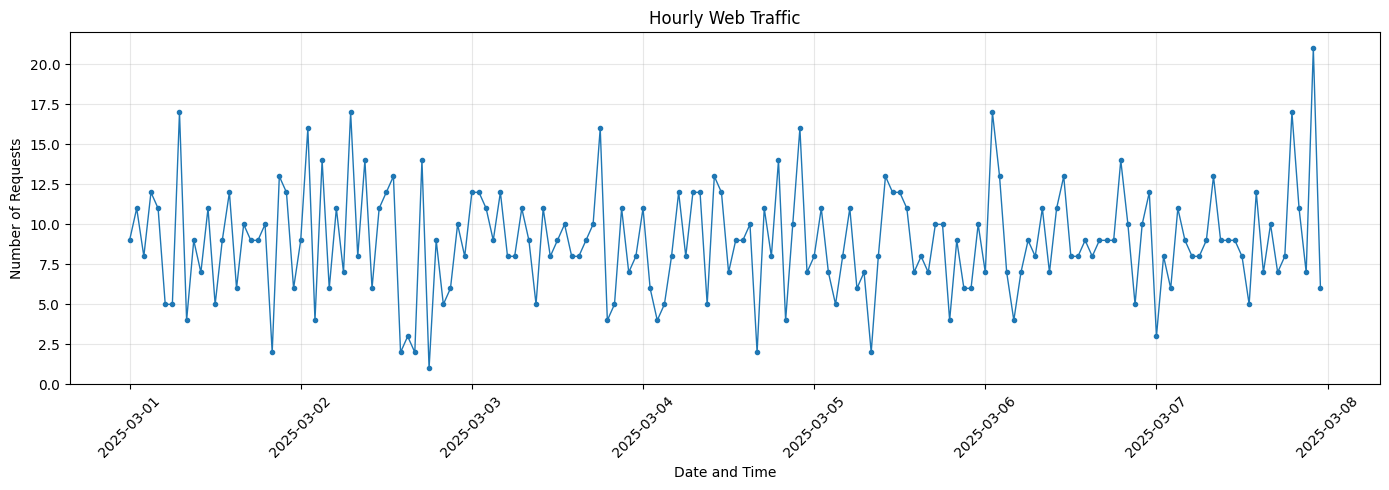

In [9]:
import matplotlib.pyplot as plt

# 1. datetime을 인덱스로 설정
logs_time = logs.set_index("datetime")

# 2. 1시간 단위로 접속 건수 집계
hourly_traffic = logs_time.resample("h").size()

# 3. 결과 출력
print("[시간별 트래픽]")
print(hourly_traffic.head(10))

print("\n전체 접속 건수:", hourly_traffic.sum())
print("시간 구간 수:", len(hourly_traffic))
print("시간당 평균 접속 건수:", round(hourly_traffic.mean(), 2))
print("최대 시간당 접속 건수:", hourly_traffic.max())

# 4. 그래프 그리기
plt.figure(figsize=(14, 5))

plt.plot(
    hourly_traffic.index,
    hourly_traffic.values,
    marker="o",
    markersize=3,
    linewidth=1
)

plt.title("Hourly Web Traffic")
plt.xlabel("Date and Time")
plt.ylabel("Number of Requests")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

요청 경로별 빈도를 분석한 결과 메인 페이지(/)가 184건(12.27%)으로 가장 높은 비율을 차지하였다. 다음으로 /search 175건, /cart 173건 순으로 나타났다. 다만 데이터 생성 과정에서 9개 경로가 동일한 확률로 선택되도록 설정되었으므로, 경로별 빈도 차이는 무작위 표본 변동의 영향으로 판단된다. 실제 고객의 페이지 선호도를 설명하기 위해서는 사용자 방문 기록 및 세션 정보 등이 추가로 필요하다.

## 1. 데이터 개요
- 로그 줄 수: 1500줄
- 기간: 2025-03-01 ~ 2025-03-07
- 추출 필드: ip, ts, method, path, status, size

## 2. 파싱 (어떻게 표로 만들었나)
- 사용한 정규식 패턴의 핵심: IP는 `\d+\.\d+...`, 시각은 `[^\]]+` 로 추출
- 날짜 형식: %d/%b/%Y:%H:%M:%S 로 파싱, 실패 0건

## 3. 트래픽 요약
- 총 요청 수: 1500
- 오류 응답(4xx·5xx) 비율: 23.2%
- 요청 많은 경로 TOP 3: /, /search, /cart

## 4. 시간 패턴 (리샘플링에서 읽은 것)
- 트래픽이 가장 몰린 시간대: 22시
- 요일/시간대 특징: .dt.hour를 활용하여 시간대별 요청 건수를 분석한 결과, 22시에 82건으로 가장 높은 접속량이 나타났다. 반면 20시는 46건으로 가장 낮은 요청 건수를 기록하였다.
## 5. 다음 분석 제안
- (오류가 잦은 경로 점검, 특정 IP의 비정상 요청 탐지 등)